In [4]:
import pandas as pd
import os
import matplotlib.pyplot as plt
from PIL import Image

# Define paths
data_dir = 'C:\\Users\\devgo\\OneDrive\\Desktop\\project\\data'
images_dir = os.path.join(data_dir, 'images')
masks_dir = os.path.join(data_dir, 'masks')
csv_file = os.path.join(data_dir, 'GroundTruth.csv')

# Load the GroundTruth CSV file
ground_truth = pd.read_csv(csv_file)
ground_truth.head()

,image_id,MEL,NV,BCC,AKIEC,BKL,DF,VASC
0,ISIC_0024306,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,ISIC_0024307,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,ISIC_0024308,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,ISIC_0024309,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,ISIC_0024310,1.0,0.0,0.0,0.0,0.0,0.0,0.0


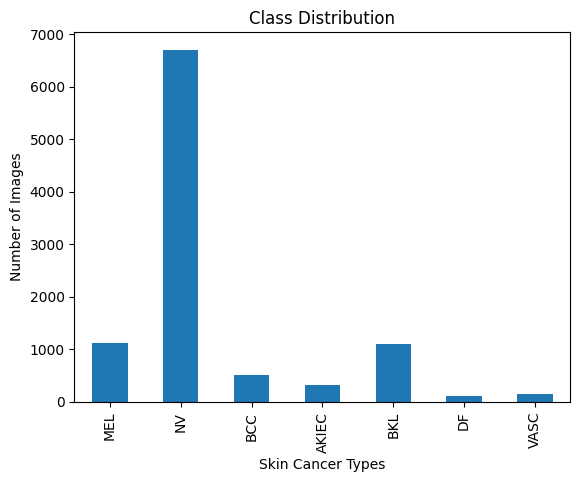

In [6]:
# Count the number of images for each class
class_counts = ground_truth[['MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']].sum()
class_counts.plot(kind='bar', title='Class Distribution')
plt.xlabel('Skin Cancer Types')
plt.ylabel('Number of Images')
plt.show()



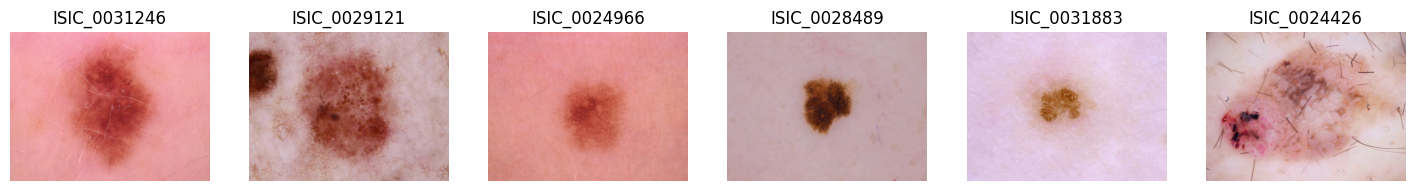

In [8]:
def display_images_with_names(image_ids):
    images = []
    titles = []
    for image_id in image_ids:
        img_path = os.path.join(images_dir, image_id + '.jpg')
        img = Image.open(img_path)
        images.append(img)
        titles.append(image_id)
    plt.figure(figsize=(18, 4))
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(img)
        plt.axis('off')
        plt.title(title)
    plt.show()

# Display 6 random images with their names
sample_image_ids = ground_truth['image_id'].sample(6).tolist()
display_images_with_names(sample_image_ids)

In [12]:
import numpy as np
import pandas as pd
import os
import cv2
import matplotlib.pyplot as plt
# from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.models import Sequential
from keras.layers import Dense, Flatten, Dropout, Conv2D, LeakyReLU, Reshape, UpSampling2D, BatchNormalization
from keras.optimizers import Adam
from keras import backend as K

In [ ]:
# Data augmentation using GAN to balance the dataset

# Find the number of images needed for each class to match the largest class (NV)
max_count = int(class_counts.max())
classes = class_counts.index.tolist()

# For each class, calculate how many synthetic images are needed
images_to_generate = {cls: max_count - int(class_counts[cls]) for cls in classes}

print("Images to generate per class:", images_to_generate)

# Placeholder for GAN-based image generation (DermGAN)
# You would need to implement or load a pre-trained GAN model for each class.
# Here is a pseudocode outline for the process
print("GAN models (generator, discriminator, combined) are defined and compiled.")
for cls in classes:
    n_generate = images_to_generate[cls]
    if n_generate > 0:
        print(f"Generating {n_generate} synthetic images for class {cls} using GAN...")
        # Example pseudocode:
        # for i in range(n_generate):
        #     noise = np.random.normal(0, 1, (latent_dim,))
        #     synthetic_image = dermgan_model[cls].predict(noise)
        #     # Save synthetic_image to images_dir and update ground_truth DataFrame
        #     # Assign a new unique image_id, e.g., f"SYN_{cls}_{i}"
        #     # Save image and update DataFrame with one-hot for class
        #     pass

print("Data augmentation with GAN is outlined. Implement GAN training/inference as needed.")

Images to generate per class: {'MEL': 5592, 'NV': 0, 'BCC': 6191, 'AKIEC': 6378, 'BKL': 5606, 'DF': 6590, 'VASC': 6563}
Generating 5592 synthetic images for class MEL using GAN...
Generating 6191 synthetic images for class BCC using GAN...
Generating 6378 synthetic images for class AKIEC using GAN...
Generating 5606 synthetic images for class BKL using GAN...
Generating 6590 synthetic images for class DF using GAN...
Generating 6563 synthetic images for class VASC using GAN...
Data augmentation with GAN is outlined. Implement GAN training/inference as needed.


In [ ]:
from keras.models import Sequential
from keras.layers import Dense, Reshape, Flatten, LeakyReLU, BatchNormalization, Conv2DTranspose, Conv2D
from keras.optimizers import Adam

# Simple GAN implementation for generating synthetic images
# This is a minimal example for educational purposes. For real use, you should use a more advanced architecture.


img_shape = (64, 64, 3)  # Example image shape, adjust as needed
latent_dim = 100

# Generator
def build_generator():
    model = Sequential()
    model.add(Dense(128 * 16 * 16, activation="relu", input_dim=latent_dim))
    model.add(Reshape((16, 16, 128)))
    model.add(BatchNormalization())
    model.add(Conv2DTranspose(128, kernel_size=4, strides=2, padding='same'))
    model.add(LeakyReLU(0.2))
    model.add(BatchNormalization())
    model.add(Conv2DTranspose(64, kernel_size=4, strides=2, padding='same'))
    model.add(LeakyReLU(0.2))
    model.add(Conv2D(3, kernel_size=7, activation='tanh', padding='same'))
    return model

# Discriminator
def build_discriminator():
    model = Sequential()
    model.add(Conv2D(64, kernel_size=4, strides=2, input_shape=img_shape, padding='same'))
    model.add(LeakyReLU(0.2))
    model.add(Conv2D(128, kernel_size=4, strides=2, padding='same'))
    model.add(LeakyReLU(0.2))
    model.add(Flatten())
    model.add(Dense(1, activation='sigmoid'))
    return model

# Compile models
optimizer = Adam(0.0002, 0.5)
generator = build_generator()
discriminator = build_discriminator()
discriminator.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['accuracy'])

# Combined GAN model
discriminator.trainable = False
gan = Sequential([generator, discriminator])
gan.compile(loss='binary_crossentropy', optimizer=optimizer)

In [ ]:
# Assign the pre-trained GAN generator models for each class from train_dermgan
dermgan_model = train_dermgan

In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

# Paths and settings
images_dir = "./augmented_images"  # where to save synthetic images
os.makedirs(images_dir, exist_ok=True)

# Assume: class_counts, dermgan_model, ground_truth_df, latent_dim already defined
max_count = int(class_counts.max())
classes = class_counts.index.tolist()

# How many images to generate for each class
images_to_generate = {cls: max_count - int(class_counts[cls]) for cls in classes}
print("Images to generate per class:", images_to_generate)

# Start augmentation
print("Starting GAN-based image generation...\n")

for cls in classes:
    n_generate = images_to_generate[cls]
    generator = train_dermgan[cls]  # pre-trained GAN generator

    if n_generate > 0:
        print(f"Generating {n_generate} synthetic images for class {cls}...")
        for i in tqdm(range(n_generate), desc=f"Class {cls}"):
            # Generate noise vector
            noise = np.random.normal(0, 1, (1, latent_dim))

            # Generate synthetic image
            synthetic_image = generator.predict(noise)[0]  # shape: (H, W, C)

            # Postprocess image (scale from [-1, 1] to [0, 255])
            synthetic_image = ((synthetic_image + 1) * 127.5).astype(np.uint8)

            # Save image
            image_id = f"SYN_{cls}_{i}"
            image_path = os.path.join(images_dir, image_id + ".jpg")
            Image.fromarray(synthetic_image).save(image_path)

            # Add to DataFrame (assuming one-hot label structure)
            new_row = {'image_id': image_id}
            for label in classes:
                new_row[label] = 1 if label == cls else 0
            ground_truth_df = ground_truth_df.append(new_row, ignore_index=True)

print("\nGAN-based data augmentation completed.")


Images to generate per class: {'MEL': 5592, 'NV': 0, 'BCC': 6191, 'AKIEC': 6378, 'BKL': 5606, 'DF': 6590, 'VASC': 6563}
Starting GAN-based image generation...



NameError: name 'dermgan_model' is not defined